# 02. Multilayer Perceptron (MLP) — Annotated Cheatsheet

Two examples: **circles (binary classification)** and **FashionMNIST (10 classes)**.
Run cells in order. Comments explain shapes, labels, losses, and the training steps.
The short lecture connections refer to *Slides_DL_1: Deep learning foundations*.

**Requirements:** PyTorch, torchvision, NumPy, Matplotlib, and scikit-learn.
FashionMNIST is downloaded on the first run; subsequent runs reuse `data/`.
A CPU works; CUDA or Apple MPS is used when available.


**This notebook follows the current 37-slide `Slides_PyTorch` deck.**
Section labels identify the corresponding slide numbers. Plotting and diagnostic
cells supplement the code shown in class. The two parts of the FashionMNIST
training loop (slides 29–30) are combined in one cell so their indentation and
execution order remain correct.

Start a fresh kernel and choose **Run All**. To restart training from scratch,
rerun setup, model construction, and DataLoader construction. The default run
uses SGD and the class-based circle MLP; optional replacements are commented out.

### Setup: run once

Choose the device once. Models and their input batches must be on the same device. `F` is the functional interface used for `F.relu` in the circle model.

In [1]:
import torch
from torch import nn
import torch.nn.functional as F

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

torch.manual_seed(42)
print("Selected device:", device)

Selected device: mps


In [2]:
# Plotting support; the slide deck shows plots without their generation code.
import numpy as np
import matplotlib.pyplot as plt

### Example 1: Circle data — binary classification

#### 1. Prepare the data

Each observation has two coordinates and a class label, 0 or 1.
`make_circles()` generates two concentric rings. A straight line cannot separate
the rings, so this is a useful example of why nonlinear hidden layers matter.


### Prepare the circle data

Each row is one point. Convert features and binary labels to `float32`. `stratify=y` preserves class proportions. Keep 800 points for training and 200 for testing.

In [3]:
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
n_samples = 1000
X, y = make_circles(n_samples=n_samples, noise=0.03, random_state=42)
X = torch.from_numpy(X).float()
y = torch.from_numpy(y).float()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

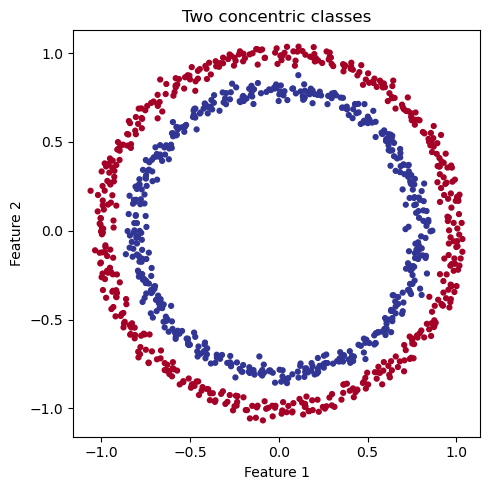

In [4]:
# The two coordinates are features; color represents the response/class.
plt.figure(figsize=(5, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="RdYlBu", s=12)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Two concentric classes")
plt.axis("equal")
plt.tight_layout()
plt.show()


### One MLP layer in PyTorch

A `Linear(2, 10)` layer has 10 neurons, each with two weights and one bias: 30 trainable parameters. ReLU changes each negative output to zero.

In [5]:
layer = nn.Linear(in_features=2, out_features=10).to(device)
hidden = F.relu(layer(X_train))  # (800, 2) -> (800, 10)

layer.weight.shape  # (10, 2): 10 neurons, 2 weights each
layer.bias.shape    # (10,): one bias per neuron

torch.Size([10])

#### 2. Build the MLP

The network is **2 → 10 → 10 → 1**: two input features, two hidden layers,
and one output score (a **logit**). `ReLU(z) = max(0, z)` is applied elementwise.

**Connection to “Why nonlinearity?”:** without ReLU, the composition of the
three affine layers would still be one affine map. More affine layers alone
would not produce the curved boundary needed here.


**Connection to “MLP for all subjects”: columns in the slides, rows in PyTorch.**

The slides use $H^{(l)}=\phi(W^{(l)}H^{(l-1)}+b^{(l)}\mathbf 1_B^\top)$,
with observations in columns. In this notebook, `H` stores observations in rows:

$$H_{\rm next}=\phi(HW^{\mathsf T}+\mathbf 1_B b^{\mathsf T}),\qquad
  H\in\mathbb R^{B\times d_{\rm in}},\quad W\in\mathbb R^{d_{\rm out}\times d_{\rm in}}.$$

Thus `nn.Linear(d_in, d_out)` computes `H @ layer.weight.T + layer.bias`.
Every observation uses the same parameters; the bias broadcasts across rows.


### The circle MLP

`__init__` constructs and registers the layers. `forward` describes the computation. The final output is a raw logit with shape `(B, 1)`. Set the seed before constructing the layers.

In [6]:
input_size, hidden_size1, hidden_size2, output_size = 2, 10, 10, 1
class TwoclassClassificationMLP(nn.Module):
    def __init__(self):
        super().__init__()  # Enable parameter/layer bookkeeping
        self.hidden1 = nn.Linear(input_size, hidden_size1)
        self.hidden2 = nn.Linear(hidden_size1, hidden_size2)
        self.output = nn.Linear(hidden_size2, output_size)
    def forward(self, x):
        x = F.relu(self.hidden1(x))  # (B, 10)
        x = F.relu(self.hidden2(x))  # (B, 10)
        return self.output(x)       # (B, 1), raw logits
torch.manual_seed(42)
model_1 = TwoclassClassificationMLP().to(device)

### Circle MLP with Sequential

This is the same 2 → 10 → 10 → 1 architecture, with 151 trainable parameters.
Uncomment `model_1 = circle_sequential` to use it **before creating the optimizer**.
A `Sequential` container passes each layer's output directly to the next layer.
Its parameter names differ from those of the custom class when saving/loading.

In [7]:
torch.manual_seed(42)  # Set before constructing the layers
circle_sequential = nn.Sequential(
    nn.Linear(input_size, hidden_size1),
    nn.ReLU(),
    nn.Linear(hidden_size1, hidden_size2),
    nn.ReLU(),
    nn.Linear(hidden_size2, output_size)   # Raw logit; no sigmoid here
).to(device)
# Optional replacement before training:
# model_1 = circle_sequential

**Connection to “Find the proper loss”: use logits during training.**

| Task | Model output fed to loss | Target in this notebook | Loss | Convert for prediction |
|---|---|---|---|---|
| Binary | One logit per example, `(B,)` after squeezing | Float 0/1, `(B,)` | `BCEWithLogitsLoss` | `sigmoid(logits)`; classify at 0.5 |
| One of K classes | K logits, `(B, K)` | Integer class index, `(B,)`, `torch.long` | `CrossEntropyLoss` | `softmax(logits, dim=1)`; choose largest |

A logit is an unrestricted score; a probability lies in $[0,1]$.
**Do not apply sigmoid or softmax before these losses.** In Example 1,
$p_i=\sigma(a_i)$ and binary cross-entropy is
$-y_i\log p_i-(1-y_i)\log(1-p_i)$.


### Binary logits and loss

`squeeze(-1)` removes only the final size-one axis, preserving the batch axis. The loss takes raw logits. Sigmoid probabilities and thresholded labels are for prediction, not for backpropagation.

In [8]:
y_logits = model_1(X_train).squeeze(-1)  # (B, 1) -> (B,)
loss_fn = nn.BCEWithLogitsLoss()
loss = loss_fn(y_logits, y_train)       # y_train: float, (B,)

probability = torch.sigmoid(y_logits)   # P(y = 1 | x)
label = (probability >= 0.5).long()   # Predicted class

### Optimizer choices

Create the optimizer after placing the model on its device. `model_1.parameters()`
identifies the weights to update. Plain SGD is active here. Uncomment only one
alternative replacement before training. Different optimizers generally need
different learning rates, chosen using validation data.

In [9]:
# Active optimizer for the circle example:
optimizer = torch.optim.SGD(model_1.parameters(), lr=0.1)
# Alternatives: uncomment ONE replacement if desired.
# optimizer = torch.optim.SGD(model_1.parameters(), lr=0.01,
#                             momentum=0.9)
# optimizer = torch.optim.Adagrad(model_1.parameters(), lr=0.01)
# optimizer = torch.optim.RMSprop(model_1.parameters(), lr=0.001)
# optimizer = torch.optim.Adam(model_1.parameters(), lr=0.001)
# optimizer = torch.optim.AdamW(model_1.parameters(), lr=0.001,
#                               weight_decay=0.01)

### Accuracy for reporting


Both arguments must have shape `(B,)`. Otherwise broadcasting can accidentally
compare every pair of labels. Equality gives True/False, `float()` converts to
1/0, and the mean times 100 gives percent accuracy. This is a reporting metric.

In [10]:
def accuracy_fn(y_true, y_pred):
    if y_true.shape != y_pred.shape:
        raise ValueError("Shapes must match.")
    return (
        (y_true == y_pred).float().mean().item() * 100)

#### 3. Train with full-batch gradient descent

Here one epoch uses all 800 training points and makes **one optimizer update**.
FashionMNIST below illustrates mini-batches and multiple updates per epoch.
Backpropagation computes gradients; `optimizer.step()` changes the parameters.


### Training the circle MLP

One epoch uses all 800 points and makes one update. Rerunning this cell continues
training the existing model; recreate the model and optimizer for a fresh run.

In [11]:
epochs = 2500
for epoch in range(epochs):
    model_1.train()                   # 1 Restore training behavior.
    y_logits = model_1(X_train).squeeze(-1)
    loss = loss_fn(y_logits, y_train)   # 2 Compute loss from raw logits.
    optimizer.zero_grad()            # 3 Clear gradients left by the preceding update.
    loss.backward()                  # 4 Compute gradients; parameters are not yet updated.
    optimizer.step()                 # 5 Update the parameters once.

#### 4. Evaluate on held-out data and visualize the boundary

`eval()` selects evaluation behavior; `inference_mode()` disables gradient
recording. Use both. If test results guide further model choices, use a separate
validation set instead, as in Example 2.


### Evaluate the circle MLP

**Slides 15**

`eval()` selects evaluation behavior; `inference_mode()` disables gradient
recording. These are separate controls. The helper already returns percent accuracy.

In [12]:
model_1.eval()  # 1 Select evaluation behavior.
with torch.inference_mode():  # 2 Do not record gradients.
    test_logits = model_1(X_test).squeeze(-1)
    test_probs = torch.sigmoid(test_logits)  # 3 Convert logits to probabilities.
    test_pred = (test_probs >= 0.5).long()
    test_loss = loss_fn(test_logits, y_test)  # 4 Measure loss using logits.
    test_acc = accuracy_fn(y_test, test_pred)
print(f"Test loss: {test_loss.item():.4f}")
print(f"Test accuracy: {test_acc:.1f}%")

Test loss: 0.0281
Test accuracy: 100.0%


In [13]:
def plot_decision_boundary(model, X, y, ax):
    """Plot a two-feature classifier without changing the model's device.

    Adapted from the original notebook's helper, credited to:
    https://madewithml.com/courses/foundations/neural-networks/
    """
    # NumPy/Matplotlib use CPU arrays; the model stays on its existing device.
    points = X.detach().cpu().numpy()
    labels = y.detach().cpu().numpy()
    parameter = next(model.parameters())

    # Build a dense grid of coordinate pairs, then predict a class at each location.
    low, high = points.min(axis=0) - 0.1, points.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(low[0], high[0], 150),
                         np.linspace(low[1], high[1], 150))
    grid = torch.as_tensor(np.column_stack((xx.ravel(), yy.ravel())),
                           dtype=parameter.dtype, device=parameter.device)

    was_training = model.training
    model.eval()
    with torch.inference_mode():
        logits = model(grid)
        # Choose from the OUTPUT shape; observed labels might omit a class.
        if logits.shape[-1] == 1:
            predicted = (logits.squeeze(-1) >= 0).long()
        else:
            predicted = logits.argmax(dim=1)  # Softmax does not change the argmax.
    model.train(was_training)  # Restore the caller's previous train/eval setting.

    regions = predicted.cpu().numpy().reshape(xx.shape)
    ax.contourf(xx, yy, regions, cmap="RdYlBu", alpha=0.35)
    ax.scatter(points[:, 0], points[:, 1], c=labels, cmap="RdYlBu", s=12)
    ax.set(xlabel="Feature 1", ylabel="Feature 2")
    ax.set_aspect("equal")


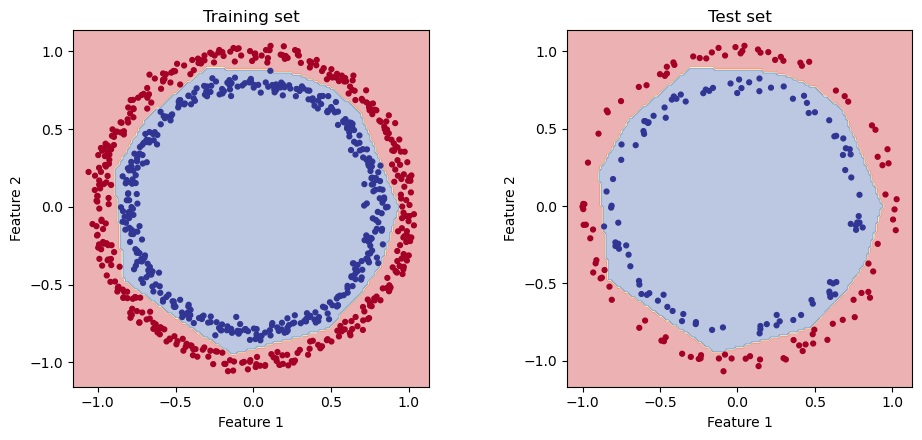

In [14]:
# Background color is the predicted class; point color is the observed class.
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
plot_decision_boundary(model_1, X_train, y_train, axes[0])
plot_decision_boundary(model_1, X_test, y_test, axes[1])
axes[0].set_title("Training set")
axes[1].set_title("Test set")
plt.tight_layout()
plt.show()

### Example 2: FashionMNIST — 10-class classification

Each example is a **28 × 28 grayscale image** of clothing, with one of 10 labels.
An MLP flattens the image into 784 input features; it does not explicitly exploit
spatial neighborhoods as a convolutional network does.

#### 1. Prepare data

The official split has 60,000 development images and 10,000 test images.
We reserve 6,000 of the development images for validation below.


### FashionMNIST inputs

`ToTensor()` changes a uint8 image to `float32` values in [0, 1] and adds a channel
axis: `(28, 28)` becomes `(1, 28, 28)`. Labels remain integer class indices.
`download=True` reuses cached files when available.

In [15]:
from torchvision import datasets
from torchvision.transforms import ToTensor

train_data = datasets.FashionMNIST(
    "data", train=True, download=True, transform=ToTensor())
test_data = datasets.FashionMNIST(
    "data", train=False, download=True, transform=ToTensor())

image, label = train_data[0]
image.shape  # (1, 28, 28): channel, height, width
class_names = train_data.classes

In [16]:
# Dataset length counts images; each image has exactly one label.
print("Development images:", len(train_data))  # 60,000; split into train/validation later.
print("Test images:", len(test_data))          # 10,000; kept separate until final evaluation.


Development images: 60000
Test images: 10000


In [17]:
# .data accesses RAW storage; dataset[i] applies ToTensor when retrieving an example.
image, label = train_data[0]
print("Raw images:", train_data.data.shape, train_data.data.dtype)  # (60000, 28, 28), uint8.
print("Transformed image:", image.shape, image.dtype)              # (1, 28, 28), float32.
print("Labels:", train_data.targets.shape, train_data.targets.dtype)  # (60000,), int64.


Raw images: torch.Size([60000, 28, 28]) torch.uint8
Transformed image: torch.Size([1, 28, 28]) torch.float32
Labels: torch.Size([60000]) torch.int64


In [18]:
# The 10 classes are represented by integers 0, ..., 9 (not one-hot vectors).
train_data.targets[:10]


tensor([9, 0, 0, 3, 0, 2, 7, 2, 5, 5])

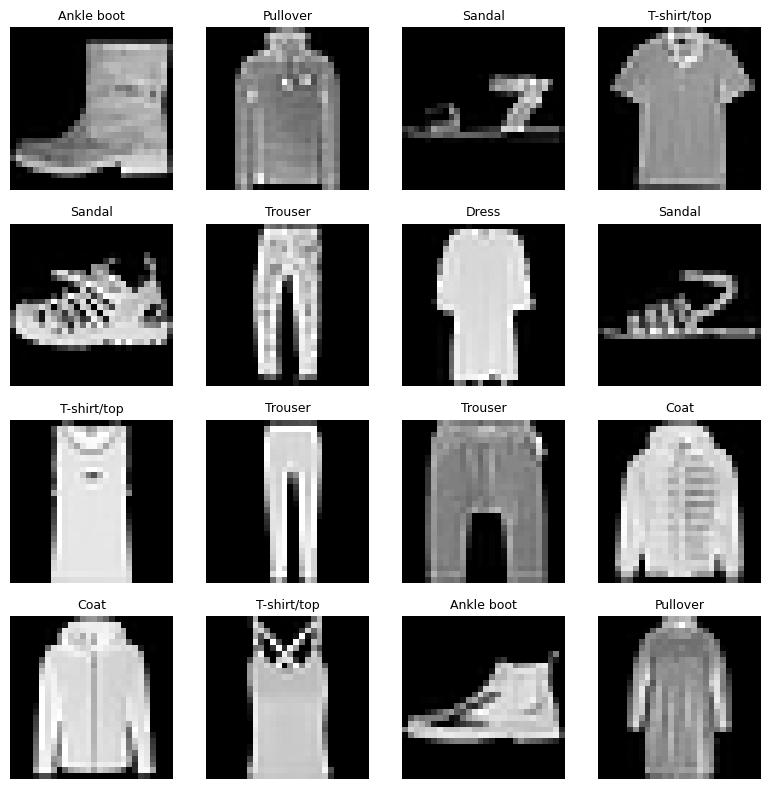

In [19]:
# A local generator makes this display repeatable without changing model initialization.
display_rng = torch.Generator().manual_seed(42)
indices = torch.randperm(len(train_data), generator=display_rng)[:16]
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for ax, index in zip(axes.flat, indices):
    image, label = train_data[index.item()]
    ax.imshow(image.squeeze(0), cmap="gray")  # Remove only the single channel axis.
    ax.set_title(class_names[label], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()


#### 1.2 Split and create DataLoaders

**Connection to “Fit, validate, then test”:** use 54,000 images to update parameters,
6,000 to select the checkpoint, and the official 10,000-image test set only at the end.
A `DataLoader` returns mini-batches and can shuffle training examples each epoch.

**Batch / step / epoch:** with batch size 64, one epoch has 844 updates:
843 full batches and a final batch of 48. The last batch is smaller because
`drop_last=False` by default. `num_workers=0` keeps loading simple and portable;
larger values use worker processes and may improve throughput in some environments.


### Datasets and data splits

`train_data[i]` retrieves one transformed image and its label. `random_split`
returns disjoint subsets with fixed membership. Its seeded generator keeps this
split independent of other random draws. The split does not stratify by class.

In [20]:
from torch.utils.data import (
    DataLoader, random_split)
image, label = train_data[0]          # 1
train_subset, val_subset = random_split(
    train_data, [54000, 6000],        # 2
    generator=torch.Generator().manual_seed(42))  # 3

### Building DataLoaders

The Dataset supplies individual examples. Each iteration of a DataLoader stacks
up to 64 image–label pairs into a batch. `shuffle=True` changes the training order
each epoch while keeping pairs together. `num_workers=0` loads in the main process.
`drop_last=False` is the default, so the final 48 training images are retained.
DataLoaders do not automatically move batches to the GPU.

In [21]:
BATCH_SIZE = 64                      # 1
train_dataloader = DataLoader(
    train_subset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0,     # 2, 3
    generator=torch.Generator().manual_seed(42))
val_dataloader = DataLoader(
    val_subset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0)
test_dataloader = DataLoader(
    test_data, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0)
# drop_last=False is the default.    # 4

### A batch, a step, an epoch

`iter(train_dataloader)` starts a pass and `next(...)` fetches one batch.
A `for images, labels in train_dataloader:` loop repeats this process automatically.
With 54,000 training images and batch size 64, there are 843 full batches plus one
batch of 48: **844 updates per epoch** when each batch gets one optimizer step.
`len(loader)` counts batches; `len(loader.dataset)` counts examples.

In [22]:
# 1. Start a pass and retrieve one batch
train_features_batch, train_labels_batch = next(
    iter(train_dataloader))
# 2. The first axis indexes examples
train_features_batch.shape  # (64, 1, 28, 28)
train_labels_batch.shape    # (64,)
# 3. Count images versus batches
len(train_dataloader.dataset)  # 54,000 images
len(train_dataloader)          # 844 batches

844

#### 2. Build the MLP

Flatten the pixels, then apply **784 → 256 → 128 → 64 → 10**.
The final 10 entries are scores for mutually exclusive classes.


### The FashionMNIST MLP

Flatten the pixels, then apply 784 → 256 → 128 → 64 → 10. The model returns ten logits for each image. Seed before initialization, not only before training.

In [23]:
class FashionMNIST_MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),  # (B, 1, 28, 28) -> (B, 784)
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 10))  # Ten raw logits
    def forward(self, x):
        return self.net(x)
torch.manual_seed(42)
model_2 = FashionMNIST_MLP().to(device)

`Flatten()` changes the representation, not the batch membership.
`Sequential()` registers the listed layers, so all their parameters are available
to the optimizer. Each `Linear` layer already initializes its weights randomly.


For target class $y_i\in\{0,\ldots,9\}$ and logits $a_{ik}$,
`CrossEntropyLoss` evaluates $-\log\operatorname{softmax}(a_i)_{y_i}$.
The slides write this using one-hot labels; integer class indices express the
same loss here. For class predictions, `logits.argmax(dim=1)` is sufficient.
Use `softmax(dim=1)` only when you need the class probabilities.


### Multiclass logits and loss

Use the batch inspected above. Move images and labels to the model device. `dim=1` is the class axis. Argmax can operate on logits directly because softmax preserves their order.

In [24]:
images = train_features_batch.to(device)
labels = train_labels_batch.to(device)
logits = model_2(images)             # (B, 10)
loss_fn = nn.CrossEntropyLoss()
loss = loss_fn(logits, labels)       # labels: int64, (B,)

probability = logits.softmax(dim=1)  # Sum to 1 across classes
prediction = logits.argmax(dim=1)   # Shape (B,)

#### 3. Mini-batch training and validation

Train for **10 epochs** as a manageable starting run (rather than the original 100).
Select the checkpoint with the smallest validation loss. This is checkpoint
selection over a fixed budget; early stopping would additionally stop the run
after a chosen patience period without improvement.

Store scalar losses with `.item()`, and weight each batch mean by its size before
averaging. This avoids retaining computation graphs and handles the smaller last batch.


### Before FashionMNIST training

Run this initialization once before the epoch loop. `history` stores Python
numbers for plotting. `best_val_loss` starts at infinity, so the first finite
validation loss establishes the initial checkpoint. `deepcopy` will preserve
saved weights while subsequent updates change the current model.

In [25]:
from copy import deepcopy
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    model_2.parameters(), lr=0.02)
epochs = 10
history = {"train_loss": [], "val_loss": [], "val_acc": []}
best_val_loss, best_epoch, best_state = (
    float("inf"), 0, None)

### Evaluation across batches


The same helper evaluates validation or test data. Every call resets its totals
and reads the device from the model. There are no gradient updates here.
Multiply each mean batch loss by its batch size, sum, and divide by the total
number of examples. This gives the smaller final batch the correct weight.

In [26]:
def evaluate_multiclass(model, loader, criterion):
    model.eval()  # 1 Evaluation behavior and no gradient recording.
    total_loss, total_correct, total_examples = 0.0, 0, 0
    model_device = next(model.parameters()).device
    with torch.inference_mode():  # 1 Evaluation behavior and no gradient recording.
        for images, labels in loader:  # 2 Iterate over all batches.
            images, labels = (
                images.to(model_device),
                labels.to(model_device))
            logits = model(images)
            batch_size = labels.size(0)
            total_loss += (
                criterion(logits, labels).item() * batch_size)
            total_correct += (
                (logits.argmax(dim=1) == labels).sum().item())
            total_examples += batch_size  # 3 Count examples for the final averages.
    return (total_loss / total_examples,
            100 * total_correct / total_examples)

### Training loop: batches / Training loop: validation

For each epoch, train over all mini-batches, then validate once. Record the
training loss, validation loss, and validation accuracy. Copy a checkpoint when
validation loss improves. Restore the selected weights after all epochs.
`model_2.train()` is necessary after the preceding validation call switched to
evaluation mode. Ten epochs give 8,440 parameter updates.

In [27]:
for epoch in range(epochs):
    model_2.train()  # 1
    total_loss, total_examples = 0.0, 0
    for images, labels in train_dataloader:  # 2
        images, labels = (
            images.to(device), labels.to(device))
        logits = model_2(images)  # 3
        loss = loss_fn(logits, labels)
        optimizer.zero_grad()  # 4
        loss.backward()
        optimizer.step()
        batch_size = labels.size(0)  # 5
        total_loss += loss.item() * batch_size
        total_examples += batch_size

# Continue the same for epoch loop:
    train_loss = total_loss / total_examples  # 1
    val_loss, val_acc = evaluate_multiclass(
        model_2, val_dataloader, loss_fn)  # 2
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    if val_loss < best_val_loss:  # 3
        best_val_loss, best_epoch = val_loss, epoch + 1
        best_state = deepcopy(model_2.state_dict())
# After all epochs:
model_2.load_state_dict(best_state)  # 4

<All keys matched successfully>

In [28]:
# Summarize the recorded history without retaining computation graphs.
for epoch, (train_ce, val_ce, val_accuracy) in enumerate(zip(
        history["train_loss"], history["val_loss"], history["val_acc"]), 1):
    print(f"Epoch {epoch:2d}/{epochs} | Train CE {train_ce:.4f} "
          f"| Validation CE {val_ce:.4f} | Validation accuracy {val_accuracy:.1f}%")
print("Restored best validation checkpoint from epoch", best_epoch)

Epoch  1/10 | Train CE 1.4748 | Validation CE 0.8465 | Validation accuracy 65.0%
Epoch  2/10 | Train CE 0.7249 | Validation CE 0.6444 | Validation accuracy 76.6%
Epoch  3/10 | Train CE 0.5762 | Validation CE 0.5437 | Validation accuracy 81.2%
Epoch  4/10 | Train CE 0.5038 | Validation CE 0.4894 | Validation accuracy 83.1%
Epoch  5/10 | Train CE 0.4631 | Validation CE 0.4566 | Validation accuracy 83.5%
Epoch  6/10 | Train CE 0.4397 | Validation CE 0.4359 | Validation accuracy 84.3%
Epoch  7/10 | Train CE 0.4183 | Validation CE 0.4500 | Validation accuracy 83.6%
Epoch  8/10 | Train CE 0.4028 | Validation CE 0.4079 | Validation accuracy 85.5%
Epoch  9/10 | Train CE 0.3867 | Validation CE 0.4244 | Validation accuracy 84.0%
Epoch 10/10 | Train CE 0.3740 | Validation CE 0.3902 | Validation accuracy 85.9%
Restored best validation checkpoint from epoch 10


### Learning curves

Training loss averages pre-update batch losses; validation uses the end-of-epoch model. The vertical line marks the selected checkpoint.

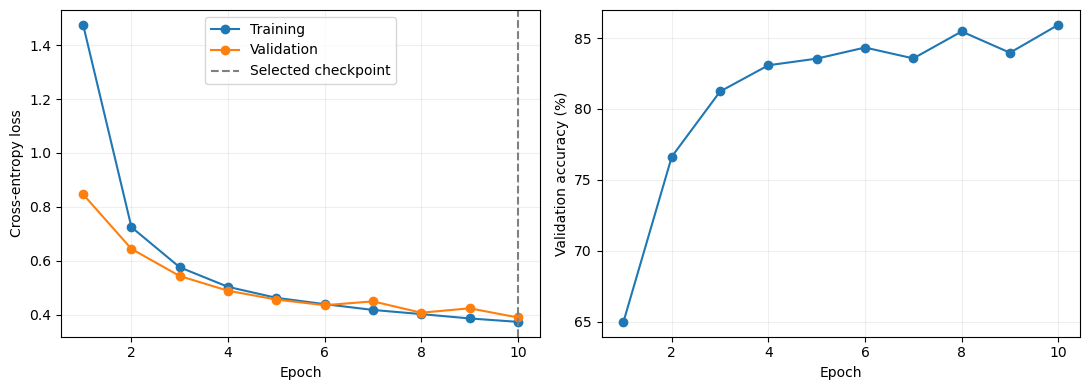

In [29]:
completed_epochs = range(1, epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(completed_epochs, history["train_loss"], marker="o", label="Training")
axes[0].plot(completed_epochs, history["val_loss"], marker="o", label="Validation")
axes[0].axvline(best_epoch, color="gray", linestyle="--", label="Selected checkpoint")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss")
axes[0].legend()
axes[1].plot(completed_epochs, history["val_acc"], marker="o")
axes[1].set(xlabel="Epoch", ylabel="Validation accuracy (%)")
for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

#### 4. Final test evaluation and saving

The selected model is now fixed. Evaluate on the test set, then save its weights.
To start a fresh training run later, recreate the model and optimizer; for an
exactly repeatable run, also recreate the shuffled DataLoader and its generator.


### Final test and predictions

Use the restored model for the final test. The preview uses the first eight images of a test batch. `preview_predictions` contains class indices; `class_names` translates them to clothing categories.

In [30]:
test_loss, test_acc = evaluate_multiclass(
    model_2, test_dataloader, loss_fn)
print(f"Test CE: {test_loss:.4f}, "
      f"accuracy: {test_acc:.2f}%")
preview_images, preview_labels = next(
    iter(test_dataloader))
model_2.eval()
with torch.inference_mode():
    preview_logits = model_2(
        preview_images[:8].to(device))
    preview_probs = preview_logits.softmax(dim=1)
    preview_predictions = preview_probs.argmax(dim=1).cpu()

Test CE: 0.4140, accuracy: 85.03%


In [31]:
print("Predicted:", [class_names[i] for i in preview_predictions.tolist()])
print("Observed: ", [class_names[i] for i in preview_labels[:8].tolist()])

Predicted: ['Ankle boot', 'Pullover', 'Trouser', 'Trouser', 'Shirt', 'Trouser', 'Coat', 'Shirt']
Observed:  ['Ankle boot', 'Pullover', 'Trouser', 'Trouser', 'Shirt', 'Trouser', 'Coat', 'Shirt']


### Inspect correct predictions and errors

The top row shows four correct predictions and the bottom row four mistakes. These examples illustrate errors; use `test_acc` for overall performance.

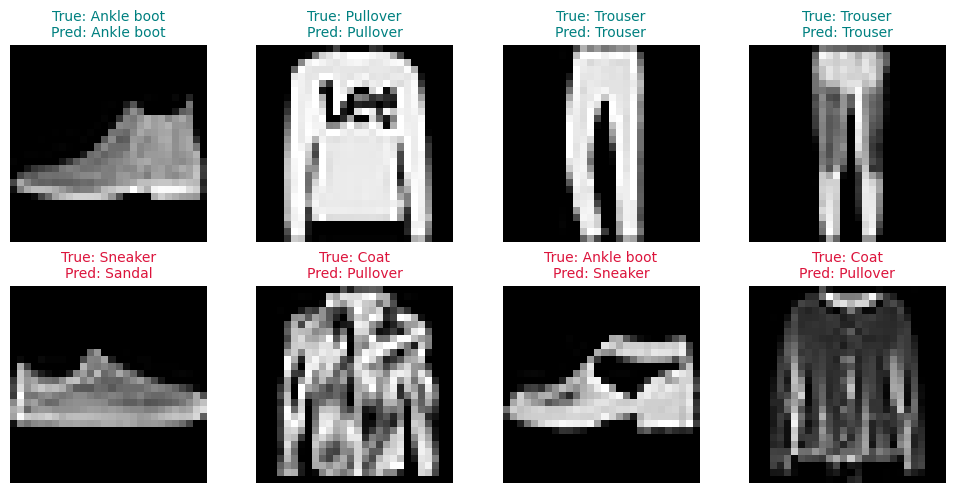

In [32]:
# Collect predictions in the fixed order of the nonshuffled test loader.
all_predictions, all_labels = [], []
model_2.eval()
with torch.inference_mode():
    for images, labels in test_dataloader:
        logits = model_2(images.to(device))
        all_predictions.append(logits.argmax(dim=1).cpu())
        all_labels.append(labels)
all_predictions = torch.cat(all_predictions)
all_labels = torch.cat(all_labels)
correct_indices = torch.where(all_predictions == all_labels)[0][:4].tolist()
error_indices = torch.where(all_predictions != all_labels)[0][:4].tolist()
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, index in zip(axes.flat, correct_indices + error_indices):
    image, label = test_data[index]
    predicted = all_predictions[index].item()
    ax.imshow(image.squeeze(0), cmap="gray")
    ax.set_title(f"True: {class_names[label]}\nPred: {class_names[predicted]}",
                 color="teal" if predicted == label else "crimson", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

### A few practical options from the slides

| Topic | Minimal PyTorch change | Key point |
|---|---|---|
| Adam | `torch.optim.Adam(model.parameters(), lr=1e-3)` | Replace SGD before training; tune the base learning rate on validation data |
| Dropout | Add `nn.Dropout(p=0.2)` after a hidden ReLU | Masks activations and rescales survivors in `train()`; acts as identity in `eval()` |
| He initialization | `nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")` | Optional initialization **before training** for a layer followed by ReLU; variance is $2/d_{\rm in}$ |

Both examples keep the default `nn.Linear` initialization. If customizing initialization,
zero biases are generally fine; identical hidden weights fail to break symmetry.
Change one option at a time and compare validation results. Rebuild the model and
optimizer before each fresh comparison.

**Official API references:** [BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html),
[CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html),
[Dropout](https://docs.pytorch.org/docs/stable/generated/torch.nn.Dropout.html),
and [initialization](https://docs.pytorch.org/docs/stable/nn.init.html).


### Dropout in code

This constructs a small demonstration module; it does not replace `model_2`.
To experiment with dropout in the full MLP, insert it after a hidden ReLU and
recreate the model and optimizer before fitting. Compare validation results.
Dropout samples a mask during `train()` and acts as the identity during `eval()`.

In [33]:
hidden = nn.Sequential(
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Dropout(p=0.2)
)

### Weight initialization

This initializes a **fresh** circle model and preserves the fitted `model_1`.
He initialization suits hidden layers followed by ReLU. The output layer uses
Xavier initialization. The trailing underscore indicates an in-place change.
Both fitted examples above use the default `nn.Linear` initialization.

In [34]:
fresh_circle = TwoclassClassificationMLP().to(device)
for layer in [fresh_circle.hidden1, fresh_circle.hidden2]:
    nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
    nn.init.zeros_(layer.bias)
# Final affine output layer:
nn.init.xavier_normal_(fresh_circle.output.weight)
nn.init.zeros_(fresh_circle.output.bias)

Parameter containing:
tensor([0.], device='mps:0', requires_grad=True)

### Saving and restoring weights

Save the selected parameters to `models/02_FashionMNIST_MLP.pth`. Recreate the
same architecture and layer names before loading. `map_location="cpu"` allows
loading without the original GPU, then `.to(device)` places the model for prediction.
Saving weights alone does not save the optimizer state or training history.

In [35]:
from pathlib import Path
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)
MODEL_SAVE_PATH = MODEL_PATH / "02_FashionMNIST_MLP.pth"
torch.save(model_2.state_dict(), MODEL_SAVE_PATH)  # 1 Save selected parameter values.
loaded_model = FashionMNIST_MLP()  # 2 Recreate the same architecture.
loaded_model.load_state_dict(torch.load(
    MODEL_SAVE_PATH, map_location="cpu", weights_only=True))
loaded_model.to(device).eval()  # 3 Prepare the loaded model for inference.
with torch.inference_mode():
    loaded_logits = loaded_model(
        preview_images[:8].to(device))
print("Reloaded predictions match:",
      torch.allclose(preview_logits, loaded_logits))  # 4 Compare original and reloaded logits.

Reloaded predictions match: True
